# Star Formation History Tables

Build a star formation history table for 600 merger trees between redshifts of $z=4.5-z~14$. I'll record the tellar mass formed in that step $M_*^{\rm new}$, the metallicity $Z$ of the gas it formed from, the stellar mass $M_*$, the dust mass $M_d$ and the intrinsic $L_{1500}$, then the average metallicity of all the stars formed in the tree $\langle Z \rangle$.

Each tree can hold several halos (the progenitors of the galaxy at the base redshift), so I've summed up the quantities over all the halos of that step. 

# Import and Path

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import smplotlib

import pandas as pd
from scipy.io import FortranFile

findfont: Failed to find font weight normal, now using 500.


In [2]:
root = Path("../").resolve()
tree_dir = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/binary_tree_n_progenitors_mh8to14_2_not_mine")
results = root / "Results_600"
zgrid = Path("/Users/dexbhadra/Documents/delphi/input_z4p5Tree_files/redshift_grid_mh8to14.bin")
out_dir = Path("data/sfh")
out_dir.mkdir(parents=True, exist_ok=True)
seeds = [12345, 13579, 24680, 32889, 98765]
for seed in seeds:
    print(f"fiducial_seed{seed}", len(list((results / f"fiducial_seed{seed}").glob("merger_tree_out_*"))), "trees")

fiducial_seed12345 600 trees
fiducial_seed13579 600 trees
fiducial_seed24680 600 trees
fiducial_seed32889 600 trees
fiducial_seed98765 600 trees


# Delphi read

In [3]:
timestep = 30e6 # yr (30 Myr)
f_yield = .14657 #Fraction of new M_* given back to gas.

In [4]:
with FortranFile(zgrid, "r") as f:
    _ = f.read_ints(np.int32)
    redshifts = f.read_reals(np.float64)   

def single_input_tree(p):
    with FortranFile(p, "r") as f:
        _ = int(f.read_ints(np.int32)[0])            # number of halos
        redshift_index_of_halos = f.read_ints(np.int32)
        _ = f.read_reals(np.float64)                  # halo mass
        descendant = f.read_ints(np.int32)            
        _ = f.read_ints(np.int32)                     # number of progenitors
    return redshift_index_of_halos, descendant

def read_output(p):
    records = []
    with FortranFile(p, "r") as f:
        while True:
            try:
                records.append(f.read_record(np.float64))
            except Exception:
                break
    sfr = records[0]
    mstar = records[1]            
    lum = records[2:-9]           
    dust = records[-7]            
    metallicity = records[-6]     
    return sfr, mstar, lum, dust, metallicity

In [5]:

def sfh_single_tree(run, tid):
    z_index, descendant = single_input_tree(tree_dir / f"merger_tree_{tid:05d}")          
    sfr, mstar, lum, dust, metallicity = read_output(run / f"merger_tree_out_{tid:04d}")
    #import pdb; pdb.set_trace()
    redshift_values = redshifts[z_index - 1]
    halos = pd.DataFrame({
        "tid" : tid,
        "z_index": z_index,
        "z":  redshift_values,
        "M_new": sfr * timestep, # Mass of new stars made in timestep
        "MZ": sfr * timestep * metallicity,  # M_new x Z of each halo, summed below to weight Z by M_new  
        "M_star": mstar, #Total stellar mass the galaxy has
        "M_dust": dust,
        "L1500": lum[2],                     # intrinsic L_lambda at
    })
    sfh = halos.groupby(["tid", "z_index", "z"], as_index=False).sum()
    sfh["Z"] = sfh["MZ"] / sfh["M_new"].where(sfh["M_new"] > 0)             
    return sfh[["tid", "z_index", "z", "Z", "M_new", "M_star", "M_dust", "L1500"]]
    
def add_average_Z(sfh):
    # Weighted by M_new
    Z_avg = {}
    for tid, tree in sfh.groupby("tid"):          # tree = the rows of one merger tree
        mass_formed = tree["M_new"].sum()
        if mass_formed > 0:
            Z_avg[tid] = (tree["M_new"] * tree["Z"]).sum() / mass_formed
        else:
            Z_avg[tid] = np.nan                   # this tree formed no stars

    sfh["Z_avg"] = sfh["tid"].map(Z_avg)          # write each tree's <Z> on all of its rows
    return sfh

In [6]:
seed = 32889
tid = 600
run = results / f"fiducial_seed{seed}"
sfh = add_average_Z(sfh_single_tree(run, tid))
sfh

,tid,z_index,z,Z,M_new,M_star,M_dust,L1500,Z_avg
0,600,1,4.50000,0.007239,3.529655e+11,4.167087e+12,1.818789e+10,1.885677e+44,0.004992
1,600,2,4.58308,0.007117,2.522864e+11,3.865856e+12,1.713441e+10,1.454741e+44,0.004992
2,600,3,4.66934,0.006822,2.961534e+11,3.650547e+12,1.570506e+10,1.609398e+44,0.004992
3,600,4,4.75899,0.006767,2.013098e+11,3.397801e+12,1.484891e+10,1.216178e+44,0.004992
4,600,5,4.85224,0.006626,2.326448e+11,3.225997e+12,1.382903e+10,1.347500e+44,0.004992
5,600,6,4.94933,0.006433,1.607619e+11,3.027451e+12,1.258561e+10,1.110192e+44,0.004992
6,600,7,5.05053,0.006195,4.053397e+11,2.890252e+12,1.167420e+10,2.085517e+44,0.004992
7,600,8,5.15611,0.005780,2.542701e+11,2.544323e+12,1.058276e+10,1.410232e+44,0.004992
8,600,9,5.26639,0.005598,2.347854e+11,2.327321e+12,9.518394e+09,1.295920e+44,0.004992
9,600,10,5.38173,0.005313,1.468788e+11,2.126948e+12,8.626713e+09,9.433012e+43,0.004992


In [7]:
# Test: for every tree, the stellar mass at z = 4.5 is all the mass formed in the tree, 
# minus what was given back to the gas: M_star(z = 4.5) = (1 - R) x sum of M_new, with R = f_yield = 0.14657

def check(sfh, rtol=1e-10):
    mstar = sfh[sfh["z_index"] == 1].set_index("tid")["M_star"]   # DELPHI's M_star at z = 4.5, one per tree
    formed = sfh.groupby("tid")["M_new"].sum()                     # all the mass formed, one per tree
    ok = np.isclose((1 - f_yield) * formed, mstar, rtol=rtol, atol=0)
    assert ok.all()
check(sfh)


In [8]:
for seed in seeds:
    run = results / f"fiducial_seed{seed}"
    sfh_all = add_average_Z(pd.concat([sfh_single_tree(run, tid) for tid in range(1, 601)], ignore_index=True))
    print(f"seed {seed}: {len(sfh_all)} rows")
    check(sfh_all)                     # stops here with an error if any tree fails
    sfh_all.to_csv(out_dir / f"sfh_seed{seed}_all_trees.csv", index=False)


seed 12345: 20558 rows
seed 13579: 20558 rows
seed 24680: 20558 rows
seed 32889: 20558 rows
seed 98765: 20558 rows


In [9]:
seed = 32889
sfh_all = pd.read_csv(out_dir / f"sfh_seed{seed}_all_trees.csv", index_col=None)
sfh_all[sfh_all["tid"] == 600].style.hide(axis="index")    # notebook table without the index

tid,z_index,z,Z,M_new,M_star,M_dust,L1500,Z_avg
600,1,4.500000,0.007239,352965530139.614746,4167087128665.230957,18187890638.046177,188567712012139275080235093381525864259256320.000000,0.004992
600,2,4.583080,0.007117,252286382548.761871,3865855756278.180176,17134405414.062874,145474116580882753631684694554439126295248896.000000,0.004992
600,3,4.669340,0.006822,296153370774.794006,3650546988819.589844,15705063261.361343,160939786941660877623850040032166968888918016.000000,0.004992
600,4,4.758990,0.006767,201309825526.288391,3397800817599.256836,14848908439.781927,121617841591657311892709659792079618733768704.000000,0.004992
600,5,4.852240,0.006626,232644823258.867004,3225996973200.356934,13829032822.510036,134749981065825945139777927862595214853013504.000000,0.004992
600,6,4.949330,0.006433,160761915732.042755,3027450901686.541992,12585605846.979050,111019157768833589403471017636809942547562496.000000,0.004992
600,7,5.050530,0.006195,405339736240.743835,2890251859943.344727,11674203280.525969,208551739788930348205671918946548229079040000.000000,0.004992
600,8,5.156110,0.005780,254270086305.418243,2544322768843.406738,10582763782.286592,141023230088510876404940626697333071048343552.000000,0.004992
600,9,5.266390,0.005598,234785360169.682007,2327321049087.773926,9518393925.983955,129592039526193314621578218850080304471736320.000000,0.004992
600,10,5.381730,0.005313,146878776147.736237,2126948179158.162109,8626713210.185720,94330121907925748427627910877309167074279424.000000,0.004992


# Plots

Panels 1-3: one merger tree (tree_id), at the steps where it formed stars. Panel 4: all 600 merger trees, one point per galaxy at $z = 4.5$.

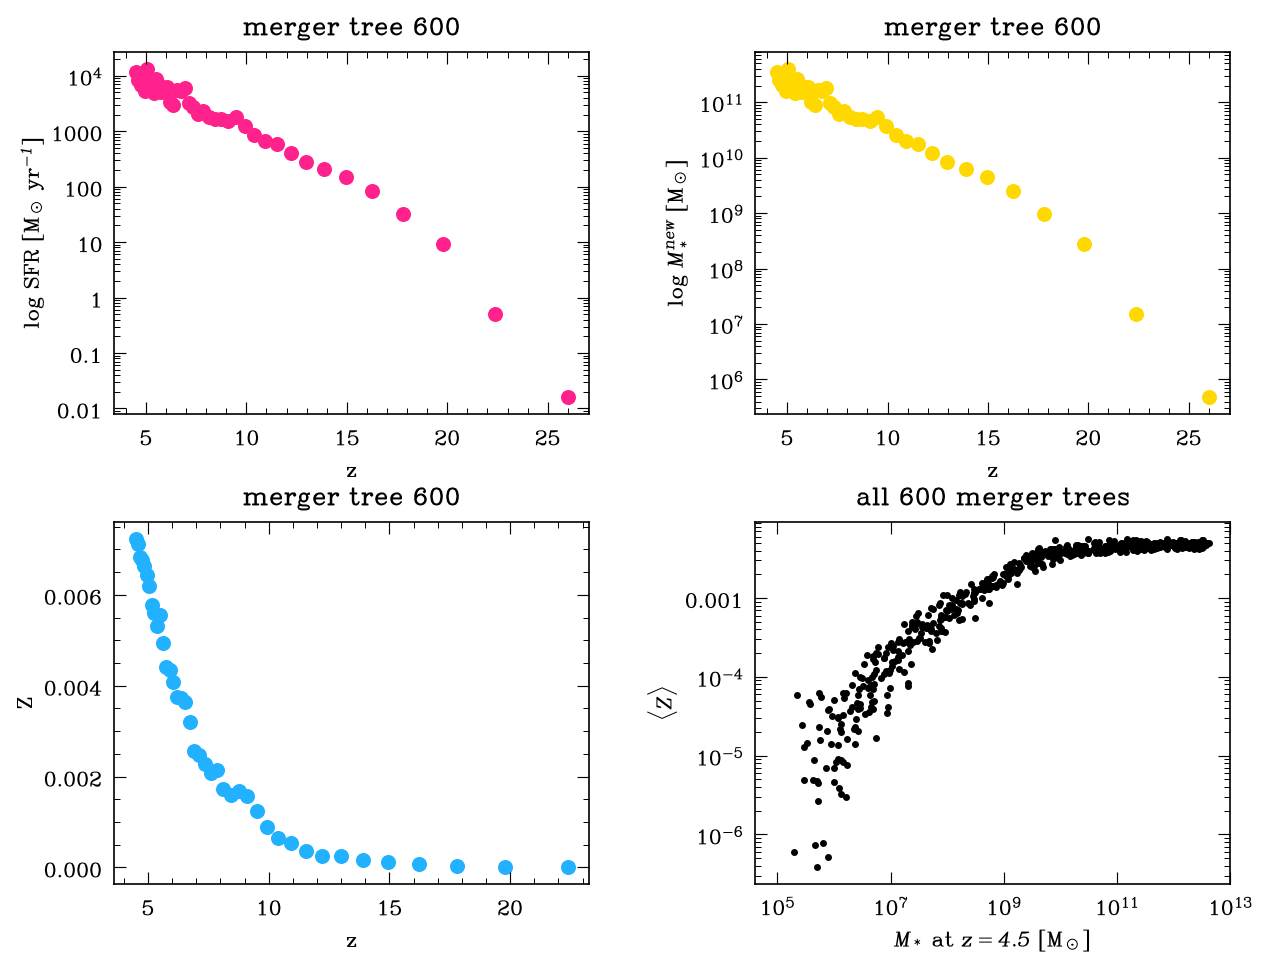

In [11]:
seed = 32889
sfh_all = pd.read_csv(out_dir / f"sfh_seed{seed}_all_trees.csv")
sfh_all["SFR"] = sfh_all["M_new"] / timestep               # Msun/yr, constant over the 30 Myr step

# one merger tree, at the steps where it formed stars
tree_id = 600
tree = sfh_all[(sfh_all["tid"] == tree_id) & (sfh_all["M_new"] > 0)]
tree_metal = tree[tree["Z"] > 0]                           # Z = 0 (metal-free gas) cannot be shown on a log axis

# all merger trees: the galaxy at z = 4.5, one row per tree (its M_star and the tree's <Z>)
galaxies = sfh_all[sfh_all["z_index"] == 1]

fig, ax = plt.subplots(2, 2, figsize=(12, 9), gridspec_kw={"wspace": 0.35, "hspace": 0.3})
ax[0][0].scatter(tree["z"], tree["SFR"], color="#FF218C")
ax[0][0].set(xlabel="z", ylabel=r"log SFR [M$_\odot$ yr$^{-1}$]", yscale="log", title=f"merger tree {tree_id}")
ax[0][1].scatter(tree["z"], tree["M_new"], color="#FFD800")
ax[0][1].set(xlabel="z", ylabel=r"log $M_*^{new}$ [M$_\odot$]", yscale="log", title=f"merger tree {tree_id}")

ax[1][0].scatter(tree_metal["z"], tree_metal["Z"], color="#21B1FF")
ax[1][0].set(xlabel="z", ylabel="Z", title=f"merger tree {tree_id}")

# x = stellar mass of the galaxy at z = 4.5, y = <Z> (trees that formed no stars have <Z> = NaN and are not drawn)
ax[1][1].scatter(galaxies["M_star"], galaxies["Z_avg"], color="black", s=10)
ax[1][1].set(xlabel=r"$M_*$ at $z = 4.5$ [M$_\odot$]", ylabel=r"$\langle Z \rangle$",
             xscale="log", yscale="log", title="all 600 merger trees")

fig.savefig("sfh_panels.png", dpi=200, bbox_inches="tight")
plt.show()
